# TP Pandas de Martin ZOBEL et Bérénice HIRIBARREN

Vous pouvez faire des cellules de type Markdown pour écrire du texte.
En mettant des # vous pouvez créer des titres et sous titre

## Todo:
* Télécharger un dataset sur data.gouv.fr
* Le référencer via son lien
* Etudier ce dataset sur pandas
* Garder les output des cellules
* Vérifier que toutes les cellules marchent
* Avant de rendre, faire Kernel -> Restart Kernel and run all cells
* Faire l'évaluation du cours

In [12]:
import pandas as pd
df=pd.read_csv("festivals-global-festivals-pl.csv",sep=';')

import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

In [13]:
df.head()

,﻿Nom du festival,Envergure territoriale,Région principale de déroulement,Département principal de déroulement,Commune principale de déroulement,Code postal (de la commune principale de déroulement),Code Insee commune,Code Insee EPCI,Libellé EPCI,Numéro de voie,...,Sous-catégorie musique,Sous-catégorie Musique CNM,Sous-catégorie cinéma et audiovisuel,Sous-catégorie arts visuels et arts numériques,Sous-catégorie livre et littérature,Période principale de déroulement du festival,Identifiant Agence A,Identifiant,Géocodage xy,identifiant CNM
0,Des Planches et des Vaches,NaN,Normandie,Calvados,Hérouville-Saint-Clair,14200,14327,200065597,CU Caen la Mer,1,...,NaN,NaN,NaN,NaN,"Bande dessinée, comics, manga",Avant-saison (1er janvier - 20 juin),NaN,FEST_14327_2572,"49.2073560619, -0.331022626025",NaN
1,Festival celte en Gevaudan,Régionale,Auvergne-Rhône-Alpes,Haute-Loire,Saugues,43170,43234,200073393,CC des Rives du Haut-Allier,1,...,Musique celtique,NaN,NaN,NaN,NaN,Saison (21 juin - 5 septembre),NaN,FEST_43234_6254,"44.9482034569, 3.53883236387",NaN
2,Festival International de Châteauroux - DARC,Interrégionale,Centre-Val de Loire,Indre,Châteauroux,36000,36044,243600327,CA Châteauroux Métropole,10 bis,...,"Chanson ou variété française, Jazz, blues, Hip...",NaN,NaN,NaN,NaN,Saison (21 juin - 5 septembre),NaN,FEST_36044_1549,"46.8029617828, 1.69399812001",NaN
3,Contre-plongées de l'été,NaN,Auvergne-Rhône-Alpes,Puy-de-Dôme,Clermont-Ferrand,63000,63113,246300701,Clermont Auvergne Métropole,NaN,...,NaN,NaN,NaN,NaN,NaN,Saison (21 juin - 5 septembre),NaN,FEST_63113_1668,"45.7856492991, 3.11554542903",NaN
4,Festival des Filets Bleus,NaN,Bretagne,Finistère,Concarneau,29900,29039,242900769,CA Concarneau Cornouaille Agglomération,NaN,...,"Chanson ou variété française, Musiques du mond...",NaN,NaN,NaN,NaN,Saison (21 juin - 5 septembre),NaN,FEST_29039_1777,"47.8966260003, -3.90716871821",NaN


Dans ce TP, nous allons étudier une base de données sur les festivals français. Avec 30 colonnes, le fichier csv fournit différentes informations sur les festivals qui existent en France, avec parfois des données manquantes dans certaines catégories ou des données rentrées de façon non conventionnelle (pour la date de création par exemple). Il va donc falloir retravailler le tableau pour produire des infographies claires

In [14]:
df.describe()

,identifiant CNM
count,958.000000
mean,2244.669102
std,1792.419130
min,2.000000
25%,638.500000
50%,1812.000000
75%,3638.750000
max,6108.000000


Les éléments du tableau sont pour la plupart des mots (en appliquant df.describe(), on se rend compte que seul l’identifiant CNN est l’objet de calculs de moyenne, minimum, etc...) En appliquant df.describe(include=‘all’), on comprend encore mieux que la plupart des valeurs ne se prêtent pas au calcul numérique

In [15]:
df.describe(include='all')

,﻿Nom du festival,Envergure territoriale,Région principale de déroulement,Département principal de déroulement,Commune principale de déroulement,Code postal (de la commune principale de déroulement),Code Insee commune,Code Insee EPCI,Libellé EPCI,Numéro de voie,...,Sous-catégorie musique,Sous-catégorie Musique CNM,Sous-catégorie cinéma et audiovisuel,Sous-catégorie arts visuels et arts numériques,Sous-catégorie livre et littérature,Période principale de déroulement du festival,Identifiant Agence A,Identifiant,Géocodage xy,identifiant CNM
count,7283,1899,7283,7257,7257,7266,7282,7247,7247,2205,...,2619,958,498,280,413,7223,826,7283,7250,958.000000
unique,7171,71,22,110,3157,2701,3112,1046,1063,342,...,802,13,176,149,186,22,826,7270,3154,NaN
top,Festival du rire,Intercommunale,Auvergne-Rhône-Alpes,Bouches-du-Rhône,Paris,35000,75056,200054781,Métropole du Grand Paris,1,...,Musiques actuelles,07- Musiques actuelles sans distinction,Court métrage,Photographie,"Bande dessinée, comics, manga",Saison (21 juin - 5 septembre),LA541,FEST__7265,"48.8567, 2.3508",NaN
freq,6,770,947,305,299,72,297,303,308,405,...,512,272,45,57,45,2644,1,10,125,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2244.669102
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1792.419130
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,638.500000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1812.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3638.750000


# Données générales sur les festivals en France

1.Nombre de festivals existant en France

In [16]:
print ('Il y a', len(df),'festivals en France')
#on compte le nombre de lignes du tableau correspondant au nombre de festivals 

Il y a 7283 festivals en France


In [17]:
df.columns = df.columns.str.replace('\ufeff', '', regex=False).str.strip() 
#le nom de la colonne 'Nom du festival' a un souci : il y a un caractère invisible, le BOM (\ufeff), au tout début du nom. Il vient du fichier CSV, lu avec un mauvais encodage. Donc on l'enlève.
l=len(df['Nom du festival'].unique()) 
#nombre de festivals qui portent un nom différent
lbis=len(df['Identifiant'].unique()) 
#'Identifiant' est un identifiant unique pour chaque festival (clé primaire) donc le nombre d'identifiants différents correspond au nombre de festivals différents en tout
print ('En réalité, il y a',l,'festivals qui portent des noms différents en France et',lbis,'festivals différents. Il y a donc 3 doublons dans le tableau')

En réalité, il y a 7171 festivals qui portent des noms différents en France et 7270 festivals différents. Il y a donc 3 doublons dans le tableau


In [18]:
#on enlève les doublons pour la suite 
df=df.drop_duplicates(subset="Identifiant", keep="first")
print("On vérifie qu'il y a bien",len(df),"festivals différents dans le tableau désormais")

On vérifie qu'il y a bien 7270 festivals différents dans le tableau désormais


2. Nombre de festivals par région

Région principale de déroulement
Nouvelle-Calédonie              1
Polynésie française             1
Saint-Barthélemy                3
Mayotte                         9
Martinique                     15
Guyane                         19
La Réunion                     41
Guadeloupe                     44
Corse                          69
Normandie                     267
Pays de la Loire              332
Hauts-de-France               338
Centre-Val de Loire           357
Bourgogne-Franche-Comté       442
Grand Est                     468
Bretagne                      590
Île-de-France                 654
Nouvelle-Aquitaine            828
Occitanie                     903
Provence-Alpes-Côte d'Azur    942
Auvergne-Rhône-Alpes          947
Name: count, dtype: int64


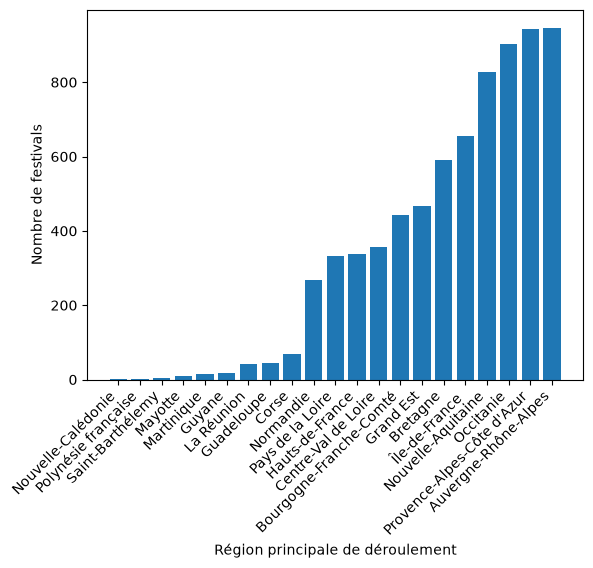

In [19]:
reg=df.groupby(['Région principale de déroulement'])['Région principale de déroulement'].value_counts() 
#on fait un groupement en fonction des régions et on compte le nombre de festivals par région 
reg=reg.sort_values() 
#on trie dans dans l'ordre croissant pour avoir un beau graphique
print(reg)
X=reg.index.to_list()
Y=reg.to_list() 
#on crée les liste abscisses et ordonnées qui correspondent aux 2 colonnes du DataFrameGroupBy (abscisse = région donc index, ordonnée = nombre donc la colonne du DataFrameGroupBy)
plt.bar(X,Y) 
#graphique en barres
plt.xticks(rotation=45, ha="right") 
#pour afficher les noms des régions afin qu'ils ne se chevauchent pas
plt.xlabel("Région principale de déroulement")
plt.ylabel("Nombre de festivals") 
#légende
plt.show()

3. Nombre de festivals créés en fonction du temps

In [20]:
dfbis=df[df['Année de création du festival'].apply(lambda x: len(str(x))==4)]
dfbis=dfbis[dfbis['Année de création du festival'].apply(lambda x: x[-1]!='e')] 
#certaines années de création ne sont pas renseignées ou sont renseignées de façon étrange (avec une date complète) donc on effectue 2 tests pour ne garder que le tableau avec les lignes dont l'année de création est une chaîne de 4 caractère qui correspond à un nombre à 4 chiffres (à l'aide de la méthode apply)

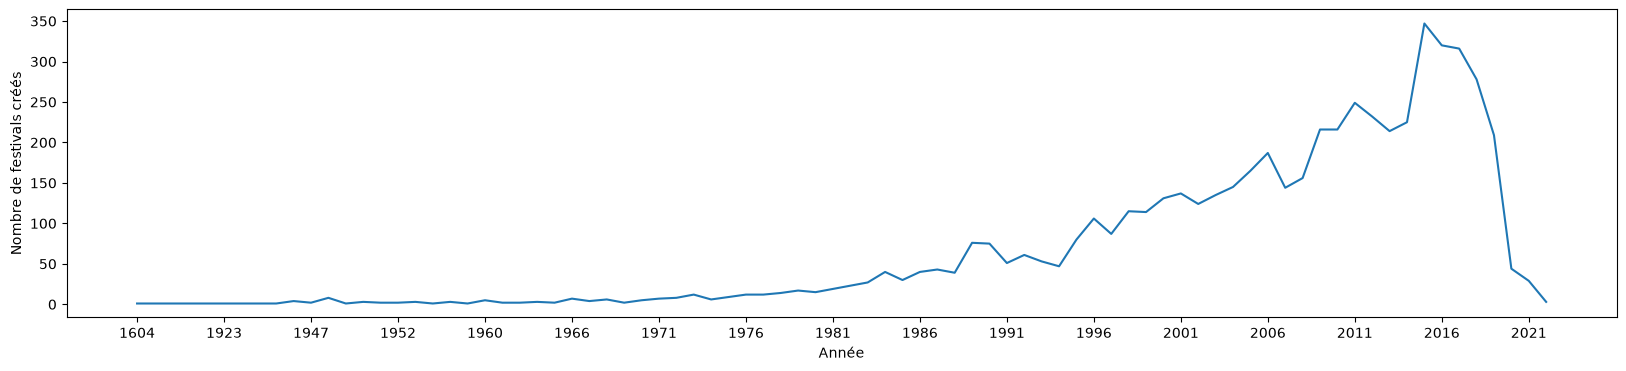

In [21]:
#dfter=(dfbis[dfbis['Année de création du festival'].notna()]) j'avais fait cette commande avant de procéder aux tests de la cellule précédente. Or ces tests enlèvent déjà les cases non remplies donc cette ligne de code devient caduque
ann=dfbis.groupby(['Année de création du festival'])['Année de création du festival'].value_counts()
#on fait un groupement en fonction de l'année de création et on compte le nombre de festivals par année
#on procède ensuite de la même manière que dans la partie précédente (avec un graphique classique et pas en barres)
X=ann.index.to_list()
Y=ann.to_list()
fig, ax = plt.subplots(figsize=(20, 4))
#on élargit la figure en largeur pour plus de visibilité
plt.plot(X,Y)
plt.xlabel("Année")
plt.ylabel("Nombre de festivals créés") 
plt.xticks(X[::5])
#on ne garde qu'une année sur 5 en abscisse pour encore plus de lisibilté (attention, l'échelle n'est pas respectée puisque il n'a pas eu un festival créé chaque année, on voit seulement la tendance ici)
plt.show()

4. Disciplines des festivals 

Les différentes disciplines des festivals sont ['Livre, littérature' 'Musique' 'Pluridisciplinaire'
 'Arts visuels, arts numériques' 'Spectacle vivant' 'Cinéma, audiovisuel']


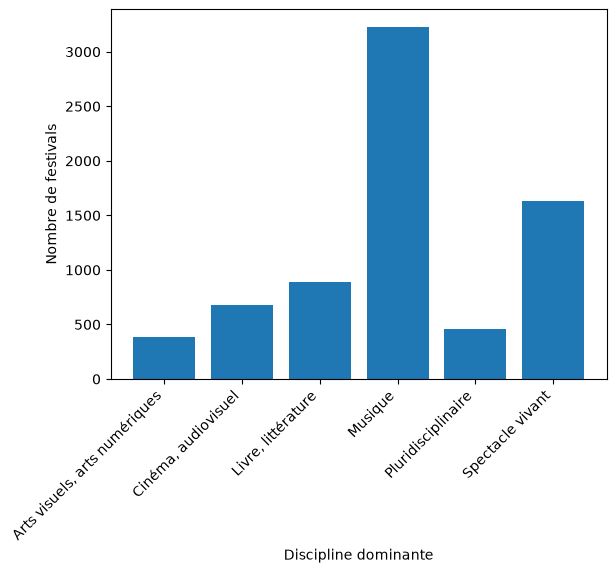

In [22]:
dff=df['Discipline dominante'].unique()
#on enregistre les différentes disciplines qui existent dans un objet de type pandas.arrays.ArrowStringArray (avec la méthode .unique())
dff=dff.to_numpy()
#on le convertit en tableau numpy pour l'afficher
print("Les différentes disciplines des festivals sont",dff)

#on procède une nouvelle fois de la même manière pour calculer le nombre de festivals par discipline (avec un groupement par discipline)
disc=df.groupby(['Discipline dominante'])['Discipline dominante'].value_counts()
X=disc.index.to_list()
Y=disc.to_list()
plt.bar(X,Y)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Discipline dominante")
plt.ylabel("Nombre de festivals")
plt.show()

5. Période du festival

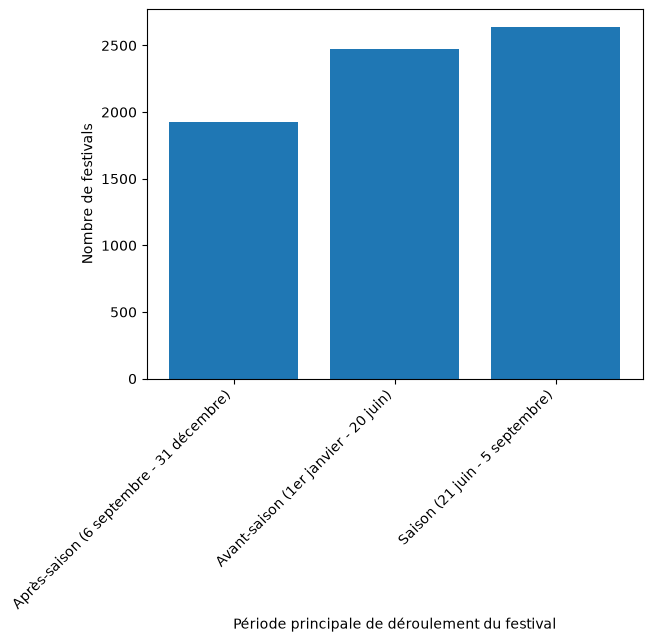

In [23]:
dfd=(df[df['Période principale de déroulement du festival'].isin(['Avant-saison (1er janvier - 20 juin)','Saison (21 juin - 5 septembre)','Après-saison (6 septembre - 31 décembre)'])])
#on ne garde du tableau initial que les lignes pour lesquelles la période de déroulement est soit Avant-saison (1er janvier - 20 juin), soit Saison (21 juin - 5 septembre), soit Après-saison (6 septembre - 31 décembre) (ces 3 catégories sont largement majoritaires donc on perd peu en information en enlevant celles qui n'y appartiennent pas)
#on procède alors exactement de la même manière que dans les 3 cas précédents avec un groupement pour afficher le nombre de festivals par période
per=dfd.groupby(['Période principale de déroulement du festival'])['Période principale de déroulement du festival'].value_counts()
X=per.index.to_list()
Y=per.to_list()
plt.bar(X,Y)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Période principale de déroulement du festival")
plt.ylabel("Nombre de festivals")
plt.show()

6. Type de festival en fonction de la période

In [24]:
dfq=dfd
#on reprend le tableau éclairci par période de déroulement créé dans la cellule précédente
dfq=dfq.pivot_table(values='Nom du festival',index='Période principale de déroulement du festival', columns='Discipline dominante',aggfunc="count")
#on utilise la méthode pivot_table pour afficher le nombre de types de festival en fonction de leur période de déroulement
dfq

Discipline dominante,"Arts visuels, arts numériques","Cinéma, audiovisuel","Livre, littérature",Musique,Pluridisciplinaire,Spectacle vivant
Période principale de déroulement du festival,,,,,,
Après-saison (6 septembre - 31 décembre),132,285,339,668,122,381
Avant-saison (1er janvier - 20 juin),135,288,401,885,177,586
Saison (21 juin - 5 septembre),102,84,126,1584,143,602


7. Carte géographique des festivals en France métropolitaine

Text(0.5, 1.0, 'Répartition géographique des festivals')

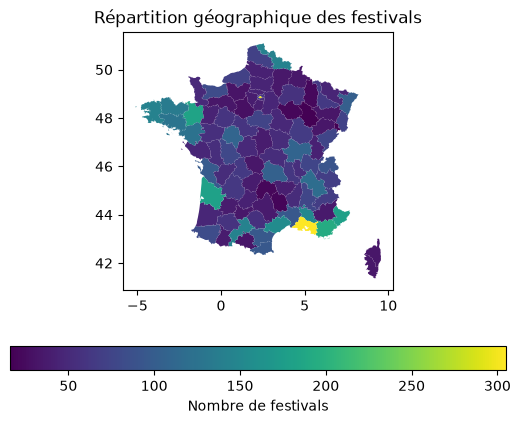

In [25]:
carte = gpd.read_file('departements.geojson')
#departements.geoijson contient les données géométriques des départements de France métropolitaine + Corse
col = df['Département principal de déroulement']
cache = (col !='Guadeloupe')&(col!='Martinique')&(col!='Guyane')&(col!='La Réunion')&(col!='Mayotte')
#on va donc retirer les départements d'outre mers dans le fichier df2
df2 = df.copy()
df2 = df2[cache]
L = df2.groupby('Département principal de déroulement')['Département principal de déroulement'].value_counts().sort_values()
#on extrait le nombre de festivals par département et on les trie par ordre croisant (pas vraiment utile en fait)
L=L.reset_index(drop=False, inplace=False).merge(carte, left_on='Département principal de déroulement', right_on='nom', how='right')
#on "aligne" les départements de L avec ceux de la carte
carte['count'] =L['count']
#on ajoute une nouvelle colonne à la carte, qui est un dataframe, qui donne le nombre de festivals par département
carte.plot(column ='count',legend=True, legend_kwds={"label": "Nombre de festivals", "orientation": "horizontal"})
#la fonction plot permet ici à la fois de tracer la carte et en même temps de représenter sous forme de couleurs le nombre de festivals par département
plt.title('Répartition géographique des festivals')
